# Phase 9 — Project summary
Final results dashboard. Every number comes from the measured report files via `src/readme_results.py` (the same code that fills the README).

In [1]:
import sys
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "base.yaml").is_file())
sys.path.insert(0, str(root))
from src import readme_results as rr
rd = next((p for p in (root / "artifacts" / "reports", root / "results" / "reports") if (p / "test_results.json").is_file()), root / "artifacts" / "reports")
R = rr.load_reports(rd)
print("reports read from:", rd.relative_to(root), "| found:", [k for k in ("audit", "val", "test", "service", "cal", "rag") if R[k]])

reports read from: artifacts\reports | found: ['audit', 'val', 'test', 'service']


## Headline and results (generated)

In [2]:
display(Markdown(rr.headline(R))); display(Markdown(rr.results(R)))

**On 300 held-out SciFact test queries, the fine-tuned retriever reaches nDCG@10 0.7131 [0.6694, 0.7567] versus 0.6451 [0.6010, 0.6900] for the pretrained `all-MiniLM-L6-v2` baseline. The paired difference is +0.0680 (95% CI [+0.0404, +0.0962]).** One training seed; sparse judgments (see Limitations).


### Data

5,183 abstracts; 1,109 claims (queries): 647 train / 162 validation (seeded, query-grouped split of the official train queries) / 300 held-out test.

### Validation (model selection)

162 queries, 177 judgments, 5,183-document candidate corpus, top-100 retrieval, one shared metric implementation for every model.

| Model | nDCG@10 | Recall@1 | Recall@5 | Recall@10 | MRR@10 | nDCG@10 95% CI |
|---|---|---|---|---|---|---|
| Baseline MiniLM-L6 (pretrained) | 0.6816 | 0.5329 | 0.7634 | 0.7932 | 0.6536 | [0.6208, 0.7404] |
| Fine-tuned (+ mined dense hard negatives) | 0.7433 | 0.6183 | 0.8117 | 0.8323 | 0.7174 | [0.6830, 0.7994] |
| Fine-tuned (positive pairs) | 0.6974 | 0.5360 | 0.7973 | 0.8364 | 0.6584 | [0.6381, 0.7535] |


Paired per-query nDCG@10 differences (bootstrap):

| Comparison (A − B) | Mean diff | 95% CI | CI excludes 0 | Better/tied/worse |
|---|---|---|---|---|
| ft_hardneg_dense − baseline | +0.0616 | [+0.0205, +0.1043] | yes | 39/106/17 |
| ft_hardneg_dense − ft_pos_only | +0.0458 | [+0.0101, +0.0828] | yes | 38/107/17 |
| ft_pos_only − baseline | +0.0158 | [-0.0154, +0.0490] | no | 19/118/25 |

Selected on validation by the pre-registered rule: **ft_hardneg_dense**. The fine-tuned models' best epoch was also chosen on these queries, so their validation scores are optimistic.

### Held-out test (evaluated once)

300 queries, 339 judgments. The frozen model and the baseline were each evaluated exactly once (ledger-enforced); no tuning followed.

| Model | nDCG@10 | Recall@1 | Recall@5 | Recall@10 | MRR@10 | nDCG@10 95% CI |
|---|---|---|---|---|---|---|
| Baseline MiniLM-L6 (pretrained) | 0.6451 | 0.4823 | 0.7379 | 0.7833 | 0.6047 | [0.6010, 0.6900] |
| Fine-tuned (+ mined dense hard negatives) | 0.7131 | 0.5782 | 0.7743 | 0.8277 | 0.6815 | [0.6694, 0.7567] |


Paired nDCG@10 difference (ft_hardneg_dense − baseline): **+0.0680**, 95% CI [+0.0404, +0.0962]; queries better/tied/worse: 74/197/29.


Change in nDCG@10 from validation to test: baseline -0.0365, ft_hardneg_dense -0.0302.

### Training (CPU, 8 GB RAM class)

| Run | Training data | Epochs | Best stage | Val nDCG@10 before | Val nDCG@10 after | Train time (s) | Peak RSS (MB) |
|---|---|---|---|---|---|---|---|
| ft_hardneg_dense | pairs + mined negatives | 2 | epoch_2 | 0.6816 | 0.7433 | 1272 | 2254 |
| ft_pos_only | pairs | 2 | epoch_2 | 0.6816 | 0.6974 | 974 | 1609 |

Validation numbers in this table come from the Sentence-Transformers evaluator; the comparison tables above use the project's own metric code (the two agreed on the pretrained model).

### Serving (packaged exact-FAISS service, CPU, sequential single-user)

| Setting | p50 ms | p95 ms | Encode ms (mean) | FAISS ms (mean) | Queries/s |
|---|---|---|---|---|---|
| top-k 1 | 15.5 | 22.9 | 15.5 | 0.86 | 60.4 |
| top-k 10 | 17.3 | 23.8 | 16.4 | 0.88 | 54.4 |
| top-k 100 | 23.3 | 30.5 | 14.4 | 0.80 | 41.7 |

Startup (excluded above): 17.8 s total (model load 17.1 s, hash verification 0.6 s). Package 115.6 MB; process RSS after load 500 MB. Reload reproduced Phase-5 rankings exactly for 162/162 validation queries.

### Optional RAG layer

_Not generated yet: run `python scripts/calibrate_rag_gate.py`._


### Provenance

Freeze fingerprint `d8e886cb5d080d5f…`; selected model weights SHA-256 `405b247000543b91…`; seed 42. Full hashes: `results/reports/model_selection.json`.


## Validation vs held-out test (nDCG@10 with 95% bootstrap CI)

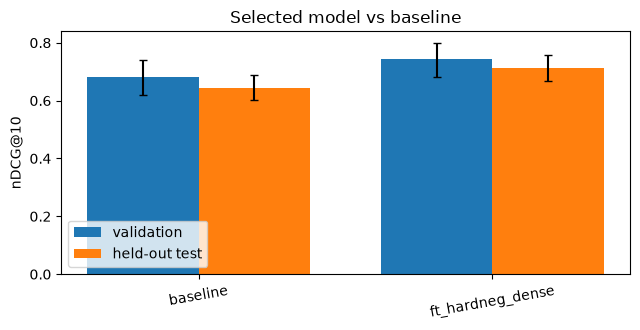

In [3]:
if R["val"] and R["test"]:
    names = [k for k in R["test"]["models"] if k in R["val"]["models"]]
    fig, ax = plt.subplots(figsize=(6.5, 3.4)); w = 0.38
    for j, (split, getter) in enumerate((("validation", lambda k: (R["val"]["models"][k]["metrics"]["ndcg@10"], R["val"]["models"][k]["bootstrap_ci"]["ndcg@10"])),
                                         ("held-out test", lambda k: (R["test"]["models"][k]["test_metrics"]["ndcg@10"], R["test"]["models"][k]["test_bootstrap_ci"]["ndcg@10"])))):
        m = [getter(k)[0] for k in names]; lo = [getter(k)[0] - getter(k)[1]["ci_low"] for k in names]; hi = [getter(k)[1]["ci_high"] - getter(k)[0] for k in names]
        ax.bar([i + (j - 0.5) * w for i in range(len(names))], m, w, yerr=[lo, hi], capsize=3, label=split)
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=10); ax.set(ylabel="nDCG@10", title="Selected model vs baseline"); ax.legend(); plt.tight_layout(); plt.show()
else:
    print("Validation and/or test results not available yet.")

## Reproducibility and publication checks

In [4]:
rows = {}
for name in ("fresh_env_report_lite.json", "fresh_env_report_full.json", "repo_hygiene_report.json", "app_smoke_report.json", "search_service_report.json", "rag_validation_report.json"):
    p = rd / name
    if p.is_file():
        import json
        d = json.loads(p.read_text(encoding="utf-8")); rows[name] = {"status": d.get("status"), "mode": d.get("mode", "")}
display(pd.DataFrame(rows).T if rows else pd.DataFrame({"note": ["no verification reports found yet"]}))
print("Run: python scripts/verify_fresh_env.py | python scripts/check_repo_hygiene.py | python scripts/generate_readme_results.py --check")

,status,mode
fresh_env_report_lite.json,PASS,lite
repo_hygiene_report.json,PASS,repo
app_smoke_report.json,PASS,
search_service_report.json,PASS,


Run: python scripts/verify_fresh_env.py | python scripts/check_repo_hygiene.py | python scripts/generate_readme_results.py --check


## Caveats
Sparse positive-only judgments; small query sets; one training seed; shared-corpus benchmark; possible overlap between the base model's pretraining mix and the corpus;
similarity is not truth; optional answers are structurally checked, not fact-checked. The dataset is CC BY-NC 2.0: see `docs/DATA_AND_LICENSES.md`.